Text(0.5, 1.0, 'FPS vs Number of apples / second')

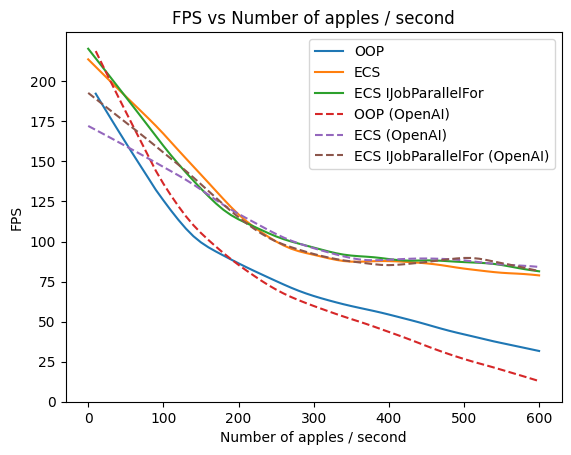

In [32]:
import pandas as pd
import statsmodels.api as sm
from matplotlib import pyplot as plt


TYPES = ['normal', 'openai']
STYLES = ['oop', 'dots', 'dots_parallel']

LABELS = {
    'oop': 'OOP',
    'dots': 'ECS',
    'dots_parallel': 'ECS IJobParallelFor'
}

for t in TYPES:
    plt.figure()
    for s in STYLES:
        df = pd.read_csv(f'{t}_{s}.csv')
        if df.empty:
            continue
        df = df.groupby('num_apples').mean()

        smoothed_data = sm.nonparametric.lowess(df['fps'], df.index, frac=0.3)

        x = smoothed_data[:, 0]
        y = smoothed_data[:, 1]

        x = x[x <= 600]
        y = y[:len(x)]

        plt.plot(x, y, label=LABELS[s])

    plt.xlabel('Number of apples / second')
    plt.ylabel('FPS')
    plt.legend()

    plt.yticks(range(0, 225, 25))

    title = f'FPS vs Number of apples / second (with OpenAI)' if t == 'openai' else f'FPS vs Number of apples / second (without OpenAI)'
    plt.title(title)
